# CAREMap · 01 Exploratory analysis

Stage 4 of the [project plan](https://claude.ai/artifact/AYBNdGqtaB2AcdvZ3tQKrc): look at the joined county table before any scoring decisions.

Input: `data/processed/county_v1_join.csv`, written by `pull_v1_data.py`.

Sections
1. Missing and withheld data
2. Distributions and skew
3. Small-county noise
4. How much the withheld business counts matter
5. Correlations between candidate indicators
6. Rural vs. urban
7. Sanity check on places we know


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

df = pd.read_csv(ROOT / "data/processed/county_v1_join.csv", dtype={"GEOID": str})
df["group"] = np.where(df["metro"] == True, "Metro", "Nonmetro")
print(f"{len(df):,} counties, {df.shape[1]} columns")
df.head()

3,144 counties, 20 columns


,GEOID,USPS,county_name,kids_under5,kids_under5_moe,rent_burden_share,price_to_income,rental_vacancy_rate,median_hh_income,cbp_estab,cbp_emp,nes_estab,rucc_2023,metro,pop_first,pop_last,pop_change_pct,cbp_withheld_0to2,nes_listed,group
0,01001,AL,Autauga County,3619,311.284436,0.346145,2.858680,0.038588,72481.0,12.0,172.0,53.0,2.0,True,58914,61920,5.102353,False,True,Metro
1,01003,AL,Baldwin County,12586,131.552271,0.471995,4.022850,0.249461,78775.0,41.0,503.0,213.0,3.0,True,233252,267761,14.794728,False,True,Metro
2,01005,AL,Barbour County,1329,117.618026,0.366234,2.452109,0.029786,46042.0,NaN,NaN,60.0,6.0,False,24958,24607,-1.406363,True,True,Nonmetro
3,01007,AL,Bibb County,1092,164.623814,0.600442,2.773072,0.062537,52541.0,NaN,NaN,21.0,1.0,True,22181,22262,0.365177,True,True,Metro
4,01009,AL,Blount County,3370,60.811183,0.422872,2.729397,0.043812,64190.0,11.0,127.0,26.0,1.0,True,59099,60156,1.788524,False,True,Metro


## 1. Missing and withheld data

Three different kinds of gap:
- **Truly missing**: the source has no value (a few ACS ratios).
- **Withheld**: County Business Patterns doesn't publish counties with fewer than 3 childcare businesses, so staff is unknown, not zero.
- **Not listed**: Nonemployer Statistics leaves out counties with no home-based providers, so these are treated as zero.

In [2]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False).to_frame("missing")
missing["share"] = (missing["missing"] / len(df)).round(3)
missing

,missing,share
cbp_emp,928,0.295
cbp_estab,928,0.295
price_to_income,6,0.002
median_hh_income,1,0.000


In [3]:
gap_by_group = df.groupby("group").agg(
    counties=("GEOID", "size"),
    cbp_withheld=("cbp_withheld_0to2", "sum"),
    nes_not_listed=("nes_listed", lambda s: (~s).sum()),
)
gap_by_group["cbp_withheld_share"] = (gap_by_group["cbp_withheld"] / gap_by_group["counties"]).round(3)
gap_by_group

,counties,cbp_withheld,nes_not_listed,cbp_withheld_share
group,,,,
Metro,1186,144,8,0.121
Nonmetro,1958,784,127,0.400


## 2. Distributions and skew

Counts (kids, workers) are heavily right-skewed, so they're plotted on a log scale. Ratios are plotted as-is.
A skew above about 1 means a few extreme counties will dominate any z-score; percentile ranks avoid that.

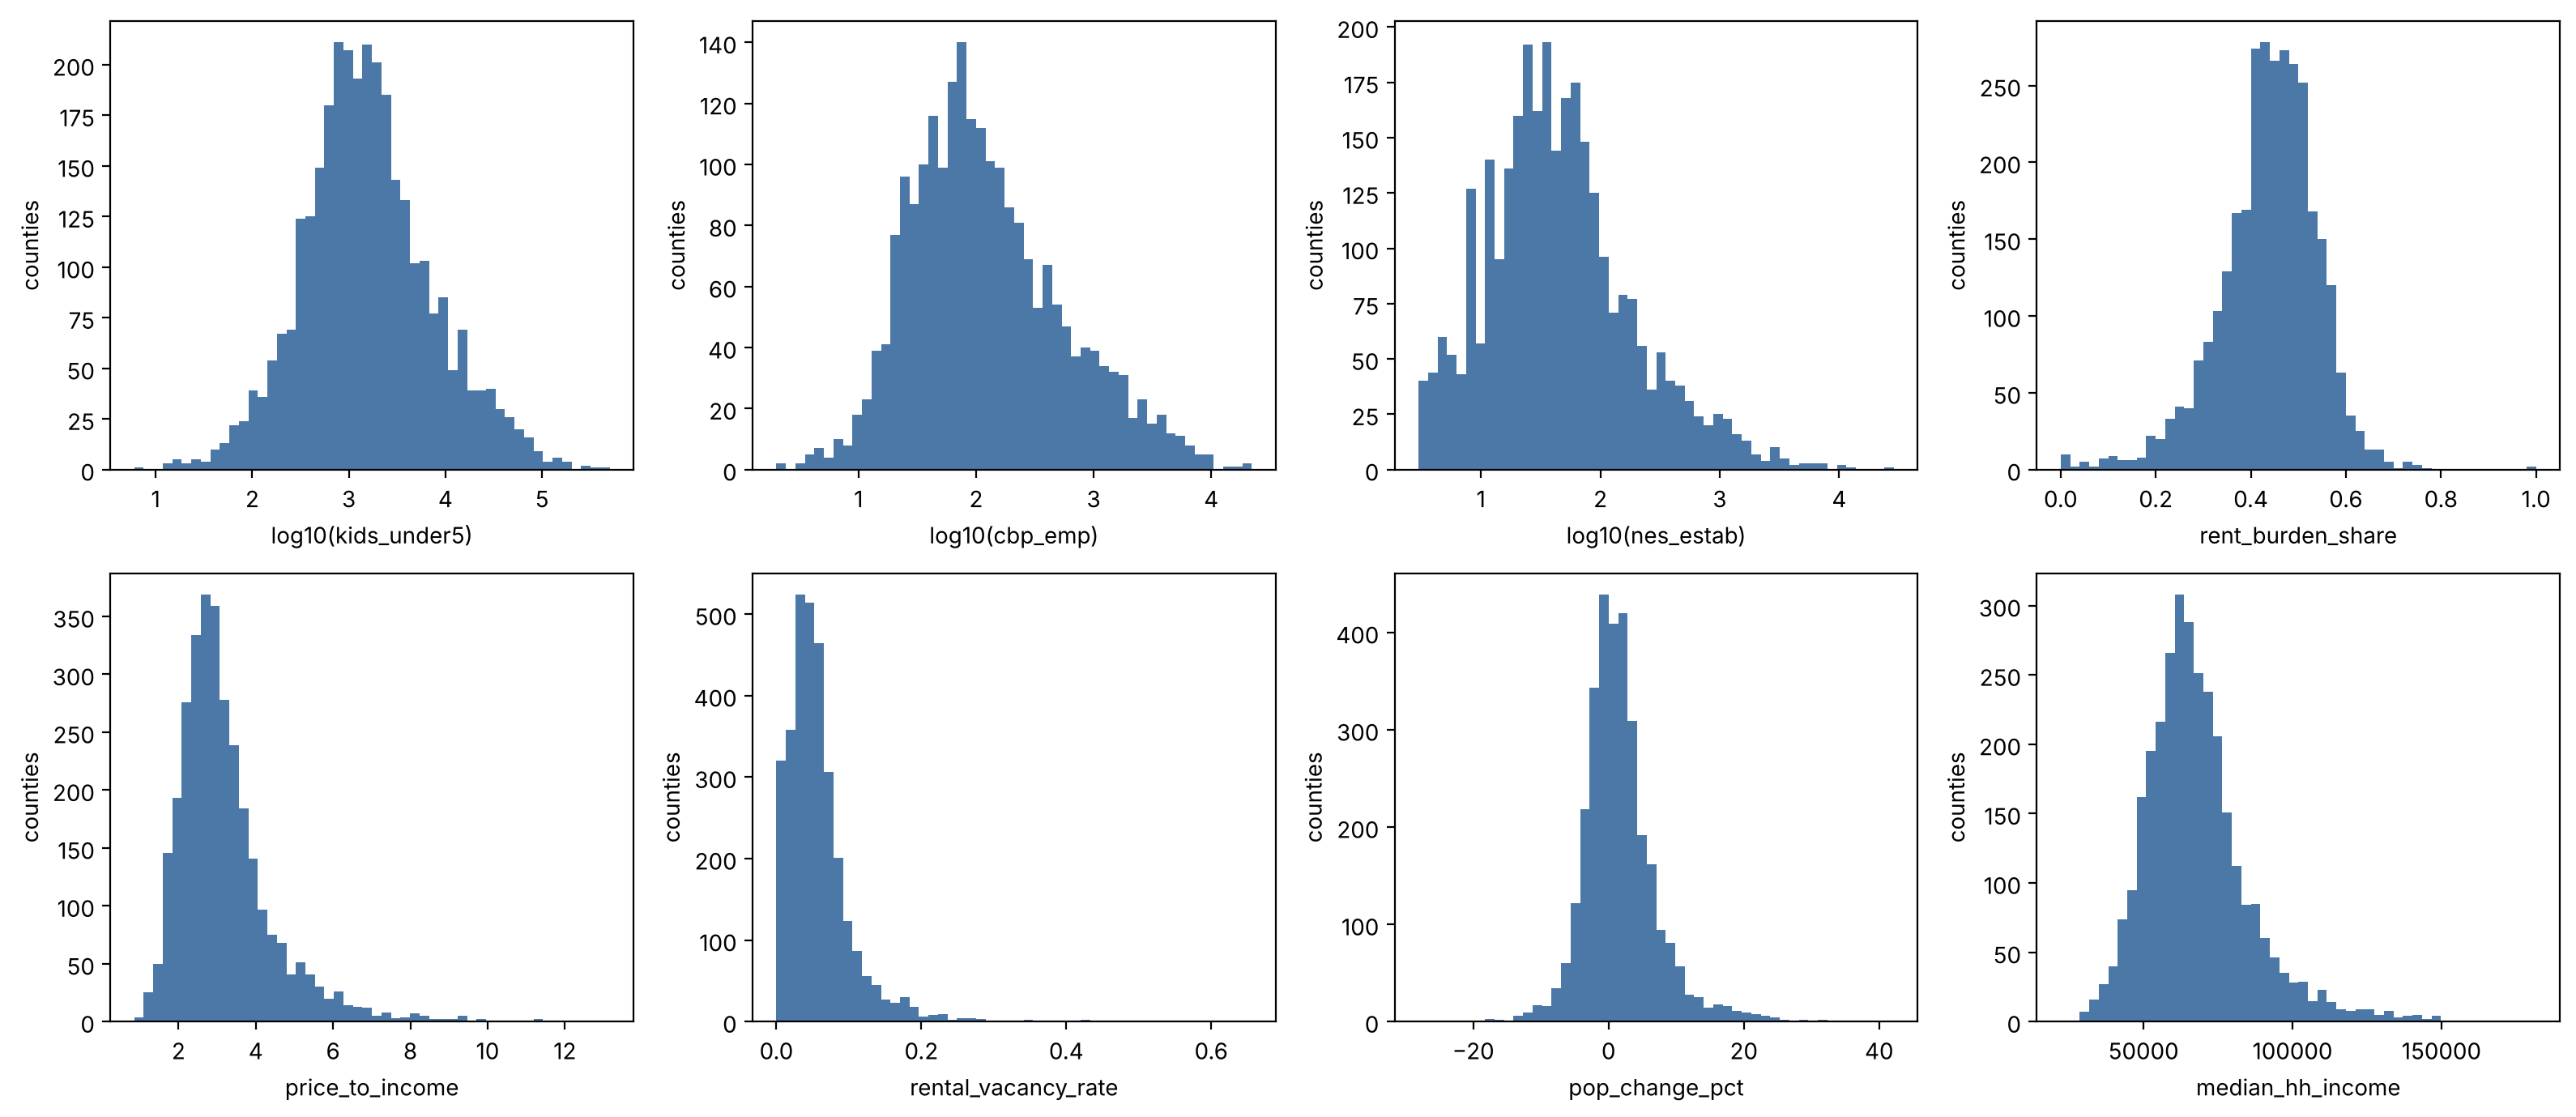

,skew
kids_under5,11.64
cbp_emp,8.01
nes_estab,20.81
rent_burden_share,-0.62
price_to_income,1.94
rental_vacancy_rate,3.06
pop_change_pct,1.11
median_hh_income,1.25


In [4]:
ratio_cols = ["rent_burden_share", "price_to_income", "rental_vacancy_rate", "pop_change_pct", "median_hh_income"]
count_cols = ["kids_under5", "cbp_emp", "nes_estab"]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, count_cols + ratio_cols):
    s = df[col].dropna()
    if col in count_cols:
        s = np.log10(s[s > 0])
        ax.set_xlabel(f"log10({col})")
    else:
        ax.set_xlabel(col)
    ax.hist(s, bins=50, color="#4C78A8")
    ax.set_ylabel("counties")
fig.tight_layout()
fig.savefig(FIG / "01_distributions.png", dpi=150)
plt.show()

df[count_cols + ratio_cols].skew().round(2).to_frame("skew")

## 3. Small-county noise

ACS estimates come with a margin of error (90% confidence). The coefficient of variation (CV) is the standard error divided by the estimate.
A CV above 0.30 is a common rule of thumb for "use with caution". The extreme ratios (100% of renters burdened, 60%+ vacancy) should cluster in small counties.

Counties with kids-under-5 CV > 0.30: 73


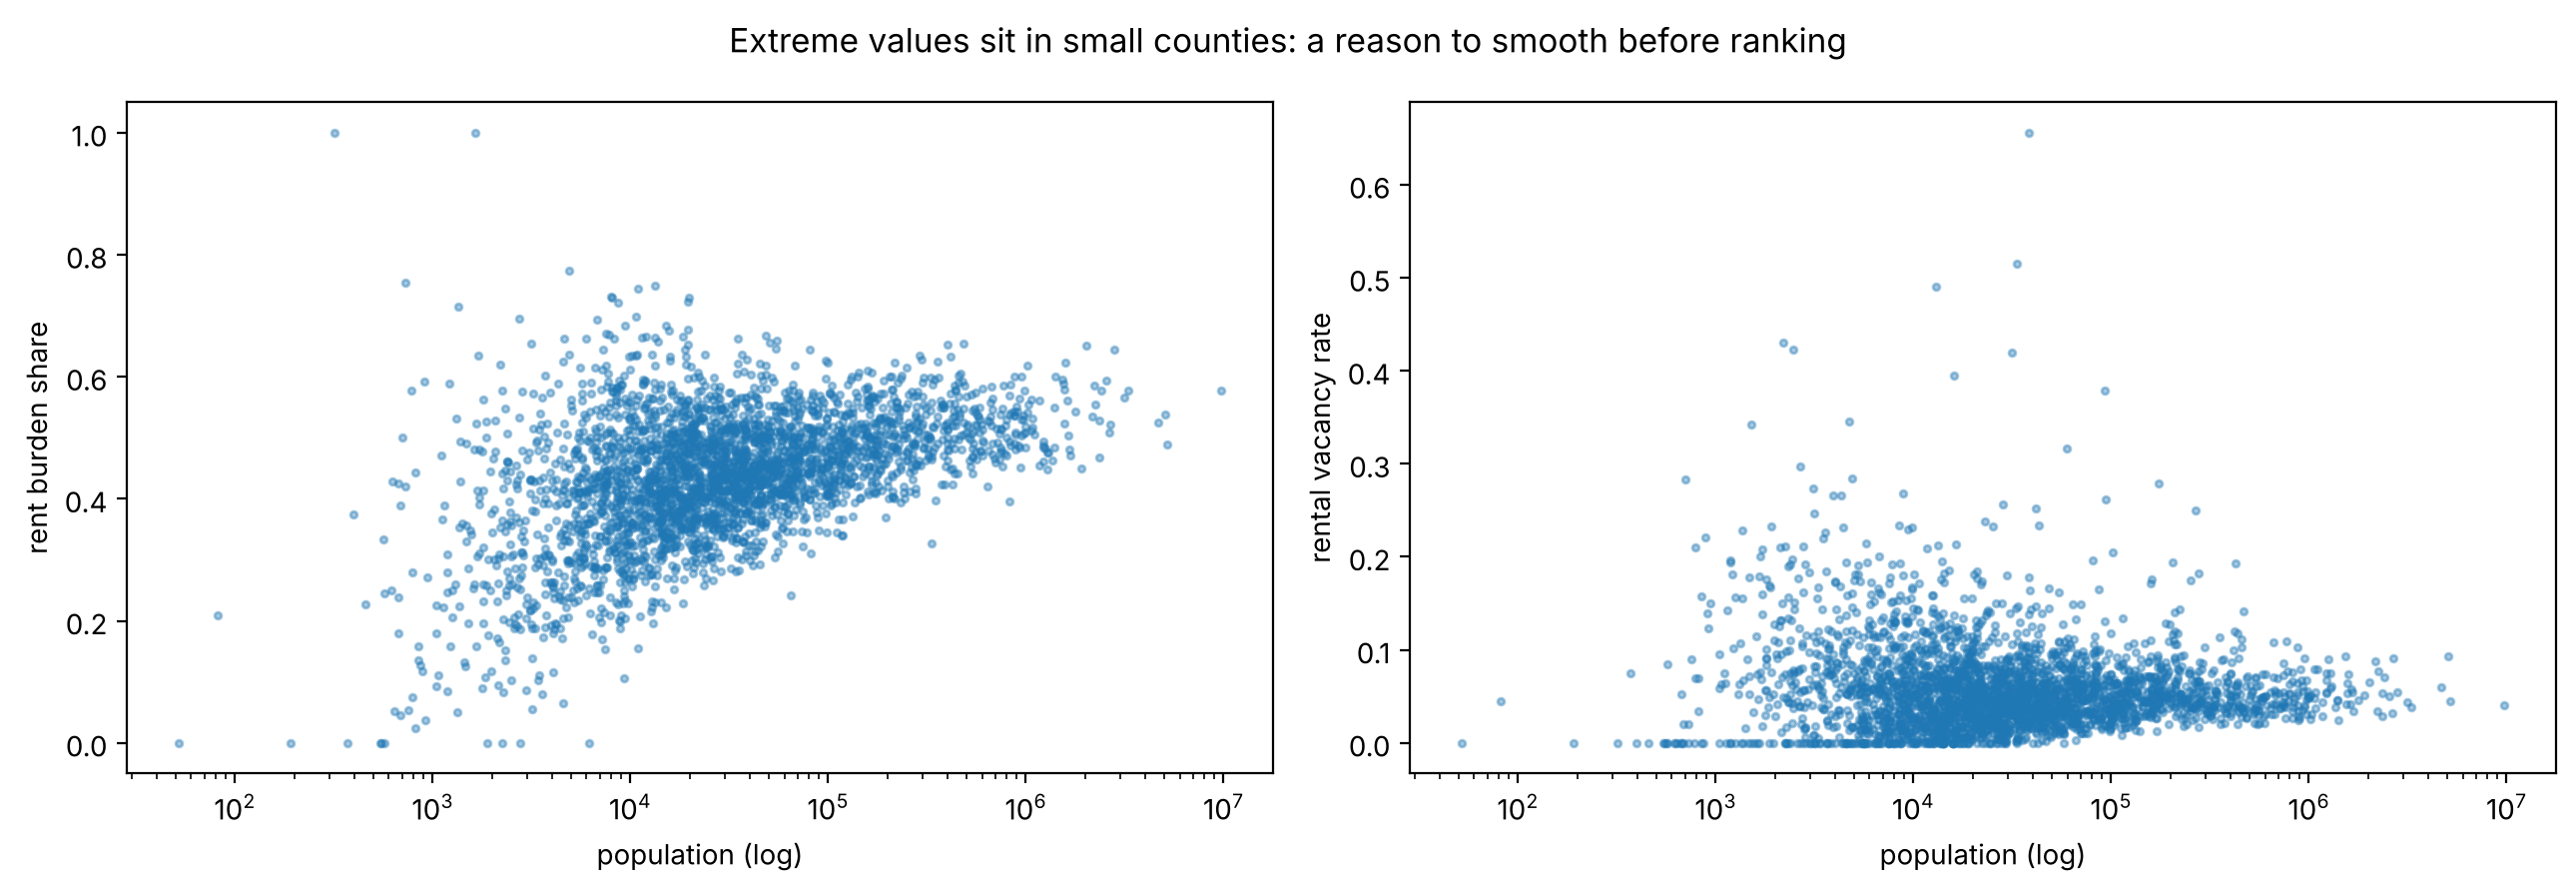

,county_name,USPS,pop_last,rent_burden_share
1803,De Baca County,NM,1647,1.000000
2655,Kenedy County,TX,319,1.000000
2989,Wahkiakum County,WA,4873,0.773885
1753,Esmeralda County,NV,729,0.754967
1128,Claiborne Parish,LA,13354,0.748806
1435,Jefferson Davis County,MS,10941,0.744467
161,Nevada County,AR,7942,0.730620
150,Lee County,AR,8029,0.730475


In [5]:
df["kids_under5_cv"] = (df["kids_under5_moe"] / 1.645) / df["kids_under5"].replace(0, np.nan)
print("Counties with kids-under-5 CV > 0.30:", (df["kids_under5_cv"] > 0.30).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(df["pop_last"], df["rent_burden_share"], s=6, alpha=0.4)
axes[0].set_xscale("log"); axes[0].set_xlabel("population (log)"); axes[0].set_ylabel("rent burden share")
axes[1].scatter(df["pop_last"], df["rental_vacancy_rate"], s=6, alpha=0.4)
axes[1].set_xscale("log"); axes[1].set_xlabel("population (log)"); axes[1].set_ylabel("rental vacancy rate")
fig.suptitle("Extreme values sit in small counties: a reason to smooth before ranking")
fig.tight_layout()
fig.savefig(FIG / "01_small_county_noise.png", dpi=150)
plt.show()

df.nlargest(8, "rent_burden_share")[["county_name", "USPS", "pop_last", "rent_burden_share"]]

## 4. How much do the withheld business counts matter?

For the 928 withheld counties we don't know employer childcare staff. Two bounds:
- **Low supply**: assume 0 employer businesses, so workers = home-based providers only.
- **High supply**: assume 2 businesses, each with the median staff of small published counties in the same metro/nonmetro group.

Kids per worker is computed under both. If the two versions rank counties almost the same way, the gap won't change conclusions much. If they disagree, the scoring has to show a range.

In [6]:
published = df[~df["cbp_withheld_0to2"] & (df["cbp_estab"] <= 5)]
staff_per_estab = (published["cbp_emp"] / published["cbp_estab"]).groupby(published["group"]).median()
print("Median staff per business in small published counties:")
print(staff_per_estab.round(1))

withheld = df["cbp_withheld_0to2"]
emp_low = df["cbp_emp"].where(~withheld, 0)
emp_high = df["cbp_emp"].where(~withheld, 2 * df["group"].map(staff_per_estab))

df["workers_low"] = emp_low + df["nes_estab"]
df["workers_high"] = emp_high + df["nes_estab"]
df["kids_per_worker_low"] = df["kids_under5"] / df["workers_low"].replace(0, np.nan)
df["kids_per_worker_high"] = df["kids_under5"] / df["workers_high"].replace(0, np.nan)

no_providers = (df["workers_low"] == 0) & (df["kids_under5"] > 0)
print(f"Counties with kids but no providers at all under the low bound: {no_providers.sum()}")

scored = df.dropna(subset=["kids_per_worker_low", "kids_per_worker_high"])
rho = scored["kids_per_worker_low"].rank().corr(scored["kids_per_worker_high"].rank())
print(f"Rank agreement between the two bounds (Spearman): {rho:.3f}")

for g, sub in scored.groupby("group"):
    r = sub["kids_per_worker_low"].rank().corr(sub["kids_per_worker_high"].rank())
    top_low = set(sub.nlargest(int(len(sub) * 0.25), "kids_per_worker_low")["GEOID"])
    top_high = set(sub.nlargest(int(len(sub) * 0.25), "kids_per_worker_high")["GEOID"])
    print(f"  {g}: Spearman {r:.3f}; top-25% overlap {len(top_low & top_high) / len(top_low):.0%}")

Median staff per business in small published counties:
group
Metro       9.7
Nonmetro    8.0
dtype: float64
Counties with kids but no providers at all under the low bound: 130
Rank agreement between the two bounds (Spearman): 0.756
  Metro: Spearman 0.894; top-25% overlap 82%
  Nonmetro: Spearman 0.700; top-25% overlap 59%


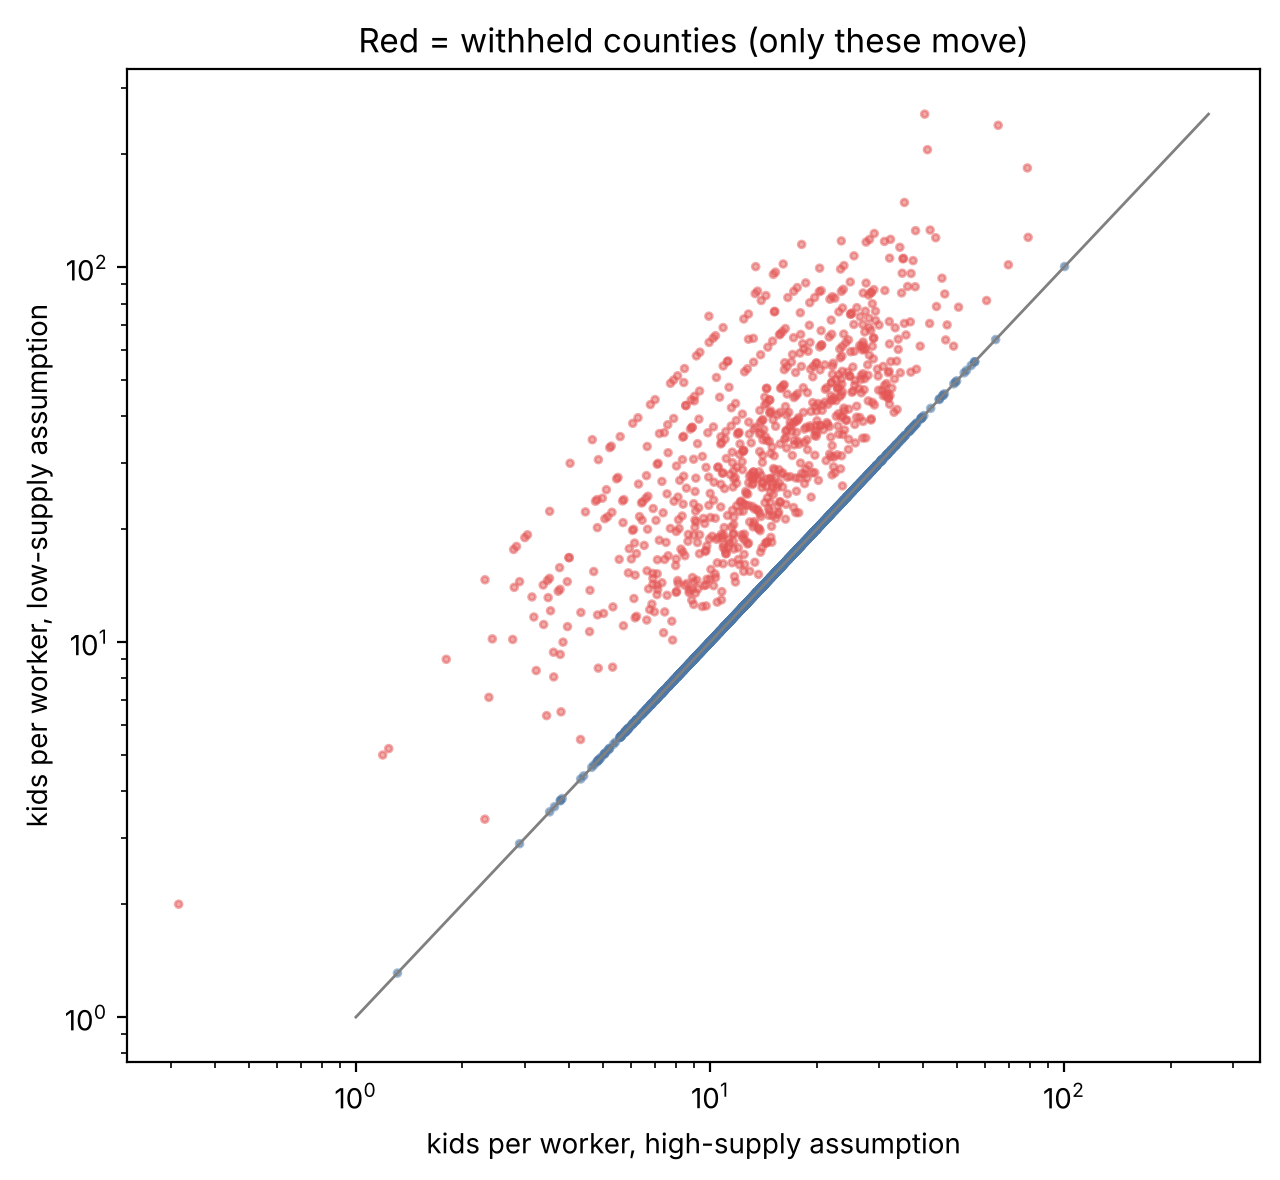

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 6))
colors = np.where(scored["cbp_withheld_0to2"], "#E45756", "#4C78A8")
ax.scatter(scored["kids_per_worker_high"], scored["kids_per_worker_low"], s=6, alpha=0.5, c=colors)
lim = [1, scored[["kids_per_worker_low", "kids_per_worker_high"]].max().max()]
ax.plot(lim, lim, color="gray", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("kids per worker, high-supply assumption")
ax.set_ylabel("kids per worker, low-supply assumption")
ax.set_title("Red = withheld counties (only these move)")
fig.tight_layout()
fig.savefig(FIG / "01_withheld_bounds.png", dpi=150)
plt.show()

## 5. Correlations between candidate indicators

Spearman (rank) correlation, because the indicators are skewed. Two indicators correlated above about 0.8 are measuring nearly the same thing, and one may be dropped or down-weighted.
The childcare measure uses the midpoint of the two bounds.

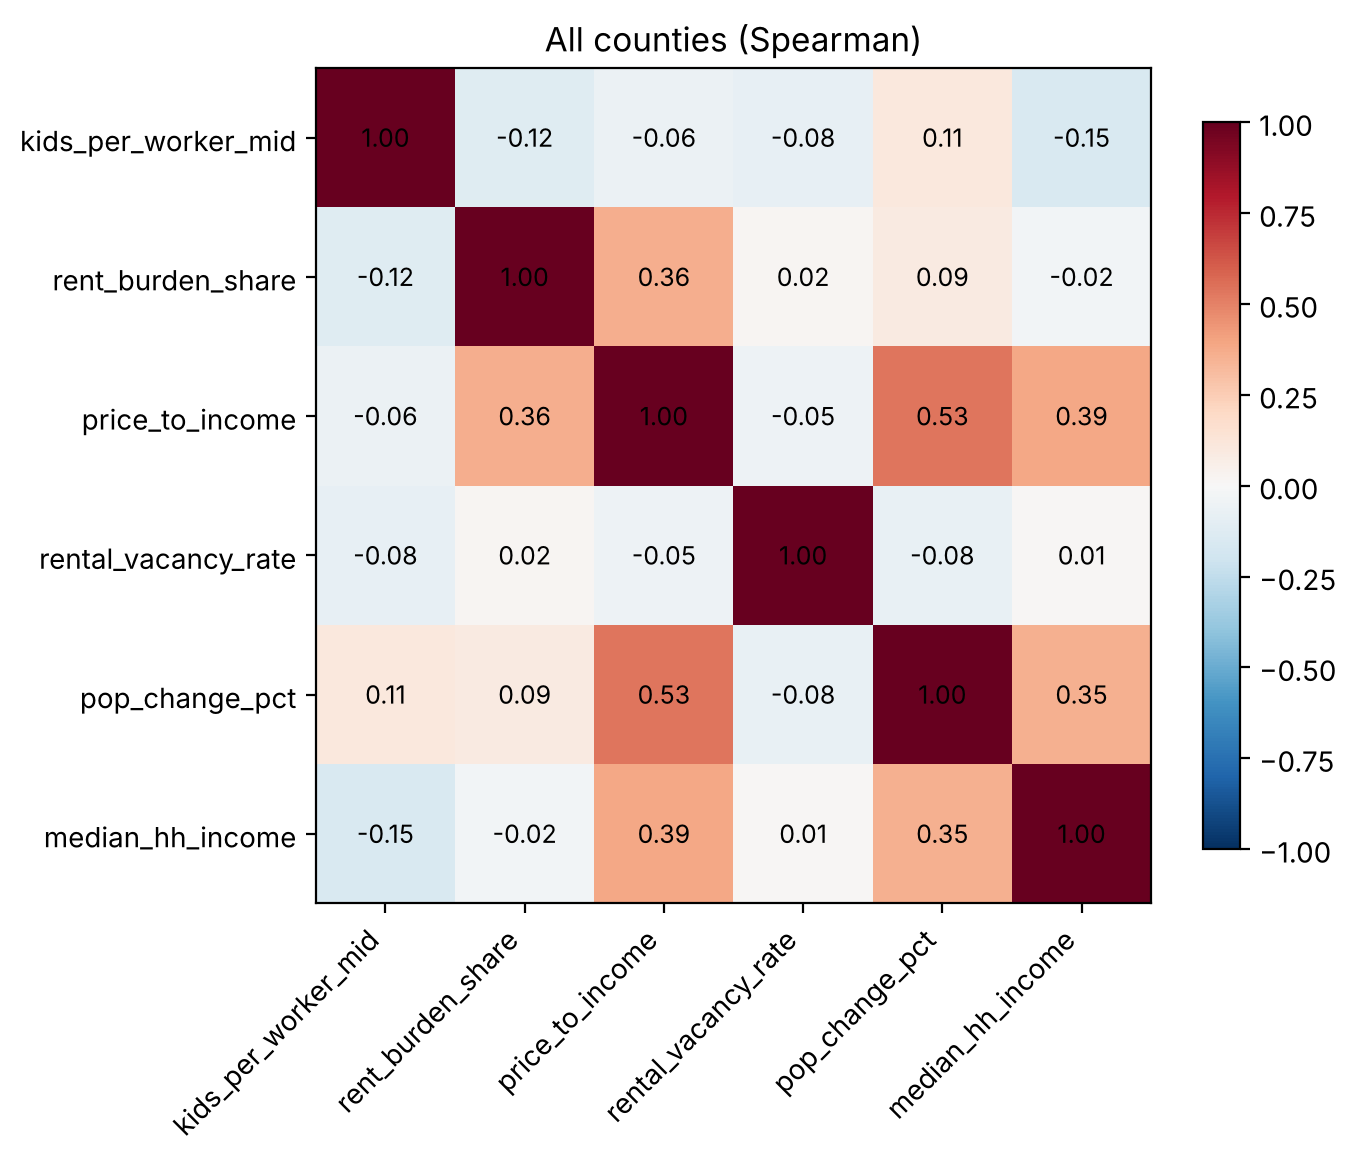

,kids_per_worker_mid,rent_burden_share,price_to_income,rental_vacancy_rate,pop_change_pct,median_hh_income
kids_per_worker_mid,1.00,-0.12,-0.06,-0.08,0.11,-0.15
rent_burden_share,-0.12,1.00,0.36,0.02,0.09,-0.02
price_to_income,-0.06,0.36,1.00,-0.05,0.53,0.39
rental_vacancy_rate,-0.08,0.02,-0.05,1.00,-0.08,0.01
pop_change_pct,0.11,0.09,0.53,-0.08,1.00,0.35
median_hh_income,-0.15,-0.02,0.39,0.01,0.35,1.00


In [8]:
df["kids_per_worker_mid"] = np.sqrt(df["kids_per_worker_low"] * df["kids_per_worker_high"])
indicators = ["kids_per_worker_mid", "rent_burden_share", "price_to_income",
              "rental_vacancy_rate", "pop_change_pct", "median_hh_income"]

def corr_plot(data, title, path):
    c = data[indicators].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(indicators)), indicators, rotation=45, ha="right")
    ax.set_yticks(range(len(indicators)), indicators)
    for i in range(len(indicators)):
        for j in range(len(indicators)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()
    return c.round(2)

corr_all = corr_plot(df, "All counties (Spearman)", FIG / "01_corr_all.png")
corr_all

In [9]:
for g, sub in df.groupby("group"):
    print(g)
    display(sub[indicators].corr(method="spearman").round(2))

Metro


,kids_per_worker_mid,rent_burden_share,price_to_income,rental_vacancy_rate,pop_change_pct,median_hh_income
kids_per_worker_mid,1.00,-0.24,-0.17,-0.10,0.13,-0.20
rent_burden_share,-0.24,1.00,0.43,0.17,-0.02,0.02
price_to_income,-0.17,0.43,1.00,0.01,0.35,0.44
rental_vacancy_rate,-0.10,0.17,0.01,1.00,-0.00,-0.08
pop_change_pct,0.13,-0.02,0.35,-0.00,1.00,0.33
median_hh_income,-0.20,0.02,0.44,-0.08,0.33,1.00


Nonmetro


,kids_per_worker_mid,rent_burden_share,price_to_income,rental_vacancy_rate,pop_change_pct,median_hh_income
kids_per_worker_mid,1.00,-0.01,0.07,-0.08,0.16,-0.07
rent_burden_share,-0.01,1.00,0.25,-0.04,0.03,-0.27
price_to_income,0.07,0.25,1.00,-0.07,0.51,0.15
rental_vacancy_rate,-0.08,-0.04,-0.07,1.00,-0.10,0.07
pop_change_pct,0.16,0.03,0.51,-0.10,1.00,0.19
median_hh_income,-0.07,-0.27,0.15,0.07,0.19,1.00


## 6. Rural vs. urban

Medians by group. If the groups differ a lot on an indicator, ranking them separately (the Stage 1 decision) matters for that indicator.

In [10]:
df.groupby("group")[indicators + ["kids_under5"]].median().round(3).T

group,Metro,Nonmetro
kids_per_worker_mid,13.952,15.787
rent_burden_share,0.478,0.427
price_to_income,3.359,2.681
rental_vacancy_rate,0.047,0.050
pop_change_pct,2.742,-0.020
median_hh_income,74993.000,61240.000
kids_under5,5415.000,845.000


## 7. Sanity check on places we know

Percentile rank within each county's own group (metro or nonmetro), where 100 = highest. For childcare, a higher kids-per-worker rank means a worse shortage; for rent burden and price-to-income, higher means more pressure; for vacancy, a lower rank means a tighter market.

In [11]:
for col in indicators:
    df[f"{col}_pctile"] = df.groupby("group")[col].rank(pct=True).mul(100).round(0)

check = ["26163", "26049", "26125", "26099", "26161"]  # Wayne, Genesee, Oakland, Macomb, Washtenaw (MI)
show = ["county_name", "USPS", "group", "kids_under5"] + [f"{c}_pctile" for c in indicators]
df[df["GEOID"].isin(check)][show]

,county_name,USPS,group,kids_under5,kids_per_worker_mid_pctile,rent_burden_share_pctile,price_to_income_pctile,rental_vacancy_rate_pctile,pop_change_pct_pctile,median_hh_income_pctile
1257,Genesee County,MI,Metro,22475,23.0,76.0,28.0,26.0,15.0,19.0
1282,Macomb County,MI,Metro,45890,76.0,67.0,38.0,22.0,30.0,57.0
1295,Oakland County,MI,Metro,65609,40.0,35.0,57.0,82.0,34.0,86.0
1313,Washtenaw County,MI,Metro,16941,10.0,89.0,77.0,32.0,20.0,77.0
1314,Wayne County,MI,Metro,110729,34.0,83.0,30.0,49.0,15.0,16.0


## Notes

Write what you see here before moving to scoring: which indicators are redundant, how much the withheld counties matter, and whether the Michigan counties look right to you.